# Оценка моделей на val и test

Прогоняет full-rank оценку (HR@K, NDCG@K) для указанных чекпойнтов на **val** и **test** сплитах.

Поддерживаемые модели: **SASRec**, **DreamRec**, **DreamRecText**, **FM-Text (FlowMatcher)**.

Что нужно сделать: в ячейке `MODELS` укажи путь к директории чекпойнта и конфиг для каждой модели. Отключить модель — `'enabled': False`.

In [1]:
import sys
import pickle
from pathlib import Path

import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

sys.path.append('../src')
from data import build_dataloaders
from evaluate import evaluate
from models.sasrec import SASRec
from models.dreamrec import DreamRec
from models.dreamrec_text import DreamRecText
from models.flow_matcher import FlowMatcher

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.spines.top']   = False
plt.rcParams['axes.spines.right'] = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')

Device: cuda


## Конфиг: какие чекпойнты оценивать

`type` — один из `sasrec`, `dreamrec`, `dreamrec_text`, `fm_text`.  
`ckpt` — директория с `best.pt` / `latest.pt`.  
`config` — yaml, по которому обучалась модель (нужен для размерностей архитектуры).

In [2]:
# ════════════════════════════════════════════════════════════════════
# Укажи здесь свои чекпойнты (edit ckpt-пути под свои прогоны)
# ════════════════════════════════════════════════════════════════════
MODELS = {
    'SASRec':       {'type': 'sasrec',        'ckpt': '../checkpoints/sasrec_baseline',              'config': '../configs/sasrec.yaml',        'enabled': True},
    'DreamRec':     {'type': 'dreamrec',      'ckpt': '../checkpoints/dreamrec_l2_nocfg',            'config': '../configs/dreamrec.yaml',      'enabled': True},
    'DreamRecText': {'type': 'dreamrec_text', 'ckpt': '../checkpoints/dreamrec_text_pca_cosine_nocfg','config': '../configs/dreamrec_text.yaml', 'enabled': True},
    'FM-Text':      {'type': 'fm_text',       'ckpt': '../checkpoints/fm_text_cosine_6',             'config': '../configs/fm_text.yaml',       'enabled': True},
}

# ─────────────────────────────────────────────────────────────────────
DATA_DIR        = Path('../data/ATG')
EMB_PATH        = DATA_DIR / '3large_emb.pickle'
WHITENING_CACHE = Path('../data/processed/whitening_cache.npz')
PADDING_IDX     = 11924
N_ITEMS         = PADDING_IDX
BATCH_SIZE      = 256
TOP_K           = (10, 20)
SEED            = 42

In [3]:
# ленивая загрузка сырых TEM-эмбеддингов (нужны только text-моделям)
_emb_raw = None
def get_emb():
    global _emb_raw
    if _emb_raw is None:
        with open(EMB_PATH, 'rb') as f:
            _emb_raw = pickle.load(f).astype(np.float32)
        print(f'Loaded embeddings: {_emb_raw.shape}')
    return _emb_raw


def load_config(path):
    with open(path) as f:
        return yaml.safe_load(f)


def build_model(mtype, cfg):
    """Собирает модель по конфигу. Веса/буферы приедут из чекпойнта."""
    d           = cfg.get('data', {})
    padding_idx = d.get('padding_idx', PADDING_IDX)
    max_seq_len = d.get('max_seq_len', 10)

    if mtype == 'sasrec':
        m = cfg['model']
        return SASRec(
            n_items=d.get('n_items', N_ITEMS), padding_idx=padding_idx,
            d_model=m['d_model'], n_heads=m['n_heads'], n_layers=m['n_layers'],
            d_ff=m['d_ff'], dropout=m.get('dropout', 0.0), max_seq_len=max_seq_len,
            tie_weights=m.get('tie_weights', True), loss=m.get('loss', 'infonce'),
            neg_ratio=m.get('neg_ratio', 64), temperature=m.get('temperature', 0.07),
        )

    if mtype == 'dreamrec':
        m = cfg['model']
        return DreamRec(
            n_items=d.get('n_items', N_ITEMS), padding_idx=padding_idx,
            d_model=m['d_model'], n_heads=m['n_heads'], d_ff=m['d_ff'],
            dropout=m.get('dropout', 0.1), max_seq_len=max_seq_len,
            T=m['T'], beta_schedule=m.get('beta_schedule', 'exp'),
            p_uncond=m.get('p_uncond', 0.0), w_cfg=m.get('w_cfg', 0.0),
            retrieval_metric=m.get('retrieval_metric', 'l2'),
        )

    if mtype == 'dreamrec_text':
        m = cfg['model']
        return DreamRecText(
            item_embeddings_raw=get_emb(), padding_idx=padding_idx,
            use_pca=m.get('use_pca', True), n_components=m.get('n_components', 256),
            per_component_whitening=m.get('per_component_whitening', True),
            whitening_cache_path=d.get('whitening_cache', WHITENING_CACHE),
            n_heads=m['n_heads'], d_ff=m['d_ff'], dropout=m.get('dropout', 0.1),
            max_seq_len=max_seq_len, T=m['T'], beta_schedule=m.get('beta_schedule', 'exp'),
            p_uncond=m.get('p_uncond', 0.0), w_cfg=m.get('w_cfg', 0.0),
            retrieval_metric=m.get('retrieval_metric', 'l2'),
        )

    if mtype == 'fm_text':
        enc, den, fm = cfg['encoder'], cfg['denoiser'], cfg['flow_matching']
        return FlowMatcher(
            item_embeddings_raw=get_emb(), padding_idx=padding_idx,
            n_components=d.get('n_components', 256),
            per_component_whitening=fm.get('per_component_whitening', False),
            whitening_cache_path=d.get('whitening_cache', WHITENING_CACHE),
            d_hidden=enc['d_hidden'], d_cond=enc['d_cond'],
            encoder_layers=enc['layers'], encoder_heads=enc['heads'],
            encoder_d_ff=enc['d_ff'], encoder_dropout=enc.get('dropout', 0.1),
            max_seq_len=max_seq_len,
            denoiser_d_block=den['d_block'], denoiser_d_ff=den['d_ff'],
            denoiser_n_blocks=den['n_blocks'], denoiser_time_emb_dim=den['time_emb_dim'],
            denoiser_dropout=den.get('dropout', 0.0),
            p_uncond=fm.get('p_uncond', 0.1), retrieval_metric=fm.get('retrieval_metric', 'dot'),
        )

    raise ValueError(f'Unknown model type: {mtype!r}')


def eval_params(mtype, cfg):
    """num_steps / w_cfg для evaluate(). Для DDPM и SASRec эти args игнорируются моделью."""
    if mtype == 'fm_text':
        return (int(cfg.get('eval', {}).get('num_sample_steps', 50)),
                float(cfg['flow_matching'].get('w_cfg', 1.0)))
    return 1, 0.0


def load_ckpt(model, ckpt_dir):
    ckpt_dir  = Path(ckpt_dir)
    ckpt_path = ckpt_dir / 'best.pt'
    if not ckpt_path.exists():
        ckpt_path = ckpt_dir / 'latest.pt'
    if not ckpt_path.exists():
        raise FileNotFoundError(f'Нет best.pt/latest.pt в {ckpt_dir}')
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt['model_state'])
    ema_shadow = ckpt.get('ema_shadow', {})
    if ema_shadow:
        for name, param in model.named_parameters():
            if name in ema_shadow:
                param.data.copy_(ema_shadow[name].to(device))
    model.eval()
    return ckpt, ckpt_path

## Сборка и загрузка всех моделей

In [4]:
models = {}
for name, spec in MODELS.items():
    if not spec.get('enabled', True):
        print(f'{name:<14} skipped (disabled)')
        continue
    cfg   = load_config(spec['config'])
    model = build_model(spec['type'], cfg).to(device)
    ckpt, path = load_ckpt(model, spec['ckpt'])
    ns, w = eval_params(spec['type'], cfg)
    models[name] = {'model': model, 'type': spec['type'], 'cfg': cfg,
                    'ckpt_dir': Path(spec['ckpt']), 'num_steps': ns, 'w_cfg': w}
    ep = ckpt.get('epoch', '?')
    n_par = model.param_summary()['total_trainable']
    print(f'{name:<14} {spec["type"]:<14} epoch={ep}  params={n_par:,}  ({path.name})')

print(f'\nЗагружено моделей: {len(models)}')

SASRec         sasrec         epoch=205  params=1,726,208  (best.pt)
DreamRec       dreamrec       epoch=160  params=863,552  (best.pt)
Loaded embeddings: (11924, 3072)
Computing PCA 3072d -> 256d (per_component=True)...
  PCA: 3072d -> 256d
  Variance explained: 78.2%
  per_component=True
  After projection: mean=-0.000000, per-dim var: mean=1.0000 min=1.0000 max=1.0000
  Row norm mean: 15.9434
    (expected ~16.0 for N(0,1) in 256d)
Cached to: data\processed\whitening_cache.npz
DreamRecText   dreamrec_text  epoch=480  params=1,581,056  (best.pt)
Loading whitening from cache: data\processed\whitening_cache.npz
FM-Text        fm_text        epoch=100  params=9,235,712  (best.pt)

Загружено моделей: 4


In [5]:
loaders = build_dataloaders(
    data_dir=DATA_DIR, batch_size=BATCH_SIZE, num_workers=0,
    splits=('val', 'test'),
)
print(f'Val:  {len(loaders["val"].dataset):,}')
print(f'Test: {len(loaders["test"].dataset):,}')

Val:  1,941
Test: 1,942


## Оценка

In [6]:
val_results, test_results = {}, {}

for name, entry in models.items():
    print(f'Evaluating {name}...')
    for split, store in [('val', val_results), ('test', test_results)]:
        torch.manual_seed(SEED)
        store[name] = evaluate(
            model=entry['model'], dataloader=loaders[split],
            top_k_values=TOP_K, num_sample_steps=entry['num_steps'],
            w_cfg=entry['w_cfg'], device=device, show_progress=True,
        )
print('Done')

Evaluating SASRec...


Evaluating DreamRec...


Evaluating DreamRecText...


Evaluating FM-Text...


Done


In [12]:
COLS = [f'{metric}@{k}' for k in TOP_K for metric in ('HR', 'NDCG')]

def random_row():
    row = {}
    for k in TOP_K:
        row[f'HR@{k}']   = k / N_ITEMS
        row[f'NDCG@{k}'] = sum(1.0 / np.log2(r + 2) for r in range(k)) / N_ITEMS
    return row

def make_table(results):
    df = pd.DataFrame(results).T[COLS]
    df.loc['Random'] = random_row()
    return df

### Val

In [13]:
val_table = make_table(val_results)
print('VALIDATION')
print(val_table.to_string(float_format=lambda x: f'{x:.4f}'))

VALIDATION
              HR@10  NDCG@10  HR@20  NDCG@20
SASRec       0.0526   0.0351 0.0649   0.0381
DreamRec     0.0129   0.0063 0.0216   0.0085
DreamRecText 0.0160   0.0135 0.0170   0.0137
FM-Text      0.0201   0.0178 0.0237   0.0188
Random       0.0008   0.0004 0.0017   0.0006


### Test

In [14]:
test_table = make_table(test_results)
print('TEST')
print(test_table.to_string(float_format=lambda x: f'{x:.4f}'))

TEST
              HR@10  NDCG@10  HR@20  NDCG@20
SASRec       0.0433   0.0266 0.0566   0.0300
DreamRec     0.0134   0.0067 0.0227   0.0091
DreamRecText 0.0175   0.0150 0.0201   0.0156
FM-Text      0.0196   0.0161 0.0216   0.0166
Random       0.0008   0.0004 0.0017   0.0006


## Сравнение моделей (val vs test)

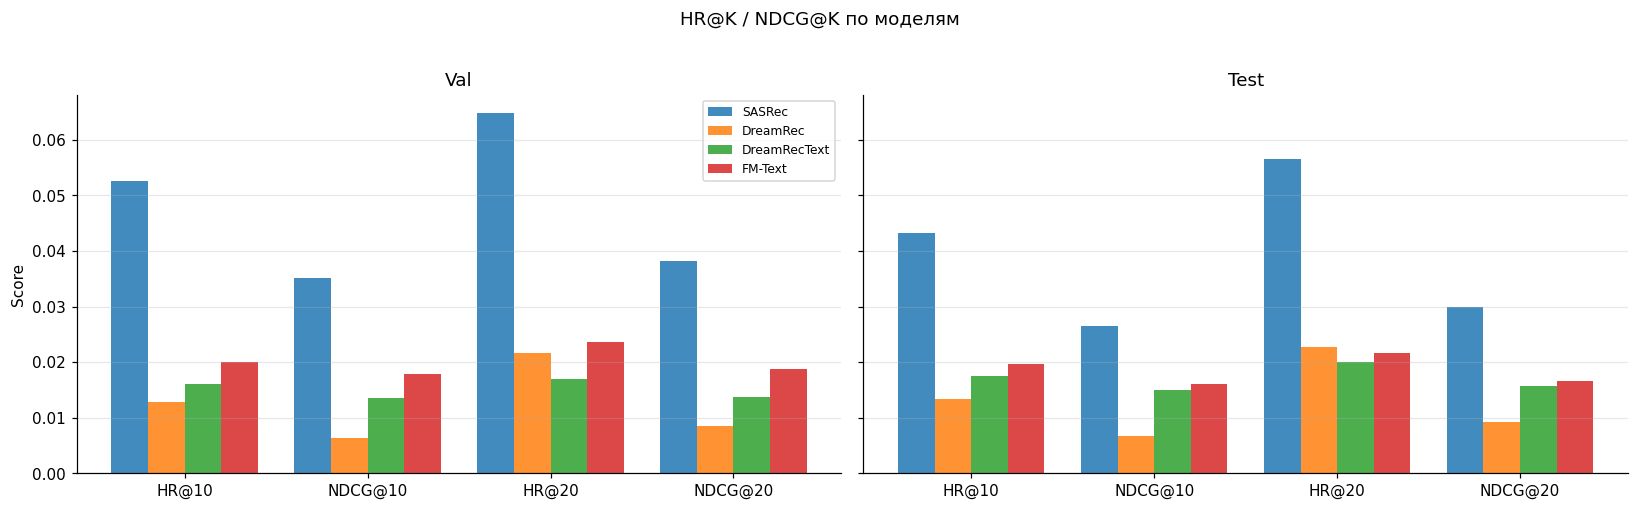

In [15]:
names   = list(models.keys())
metrics = COLS
x       = np.arange(len(metrics))
width   = 0.8 / max(len(names), 1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, results, title in [(axes[0], val_results, 'Val'), (axes[1], test_results, 'Test')]:
    for i, name in enumerate(names):
        vals = [results[name][m] for m in metrics]
        ax.bar(x + i * width, vals, width, label=name, alpha=0.85)
    ax.set_xticks(x + width * (len(names) - 1) / 2)
    ax.set_xticklabels(metrics)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Score')
axes[0].legend(fontsize=8)
plt.suptitle('HR@K / NDCG@K по моделям', y=1.02)
plt.tight_layout()
plt.show()

## Кривые обучения (val HR@20 / NDCG@20 из log_val.csv)

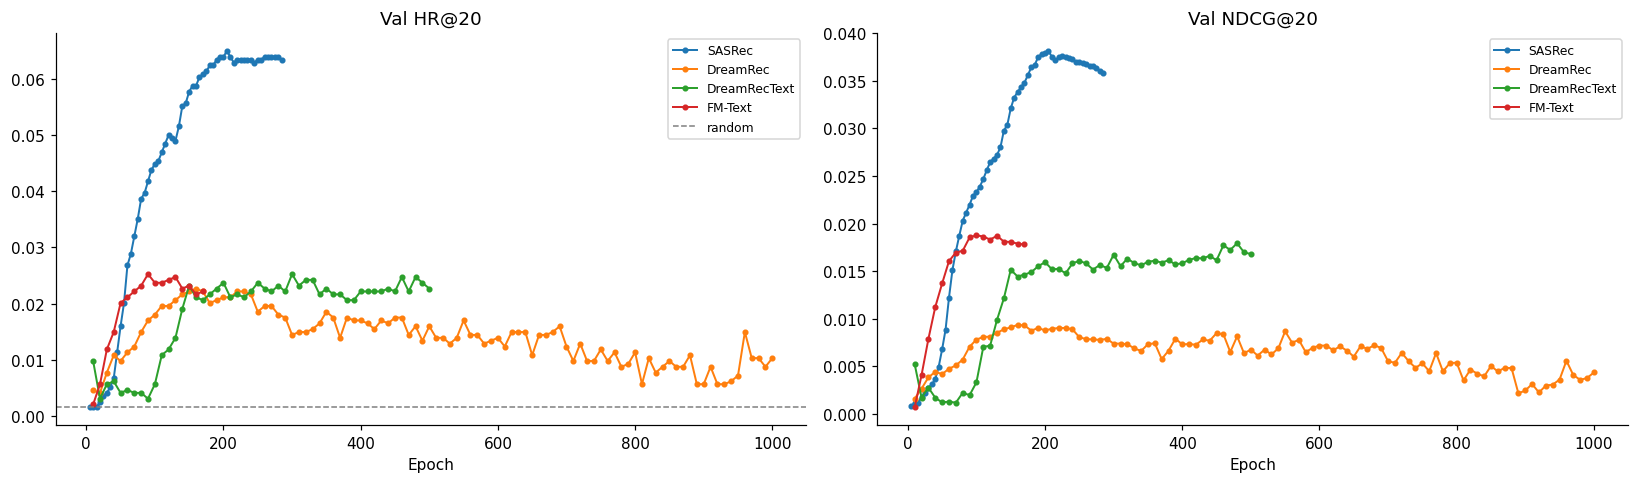

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, entry in models.items():
    log_path = entry['ckpt_dir'] / 'log_val.csv'
    if not log_path.exists():
        print(f'{name}: нет {log_path.name}')
        continue
    log = pd.read_csv(log_path)
    log = log[pd.to_numeric(log['epoch'], errors='coerce').notna()].copy()
    log['epoch'] = log['epoch'].astype(int)
    if 'HR@20' in log.columns:
        axes[0].plot(log['epoch'], log['HR@20'], 'o-', ms=3, lw=1.3, label=name)
    if 'NDCG@20' in log.columns:
        axes[1].plot(log['epoch'], log['NDCG@20'], 'o-', ms=3, lw=1.3, label=name)

axes[0].axhline(20 / N_ITEMS, color='gray', ls='--', lw=1, label='random')
axes[0].set_xlabel('Epoch'); axes[0].set_title('Val HR@20');   axes[0].legend(fontsize=8)
axes[1].set_xlabel('Epoch'); axes[1].set_title('Val NDCG@20'); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()